In [ ]:
'''
we're gonna make some training data for off center stuff!!...after a new range
'''

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt

# importlib.reload(plot_time_series)
import gc  # garbage collector
# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os

import importlib

In [ ]:
#okay so i found what we had last time in dimming_training_data.py

In [ ]:
#wait damn i forgor first i will do it with the new range of training stamps
#let's check them out

In [26]:
stamp = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/images/ztf_20220820237546_000798_zr_c01_x_0001._4_stamps.npy")

In [4]:
stamp


array([[[0.00624334, 0.00660245, 0.00632046, ..., 0.0079392 ,
         0.00688292, 0.00823027],
        [0.006488  , 0.00636676, 0.00745481, ..., 0.00822095,
         0.00768941, 0.00870718],
        [0.00648035, 0.00647218, 0.00656595, ..., 0.00816755,
         0.0075678 , 0.00840155],
        ...,
        [0.00660958, 0.00690714, 0.00702078, ..., 0.00798727,
         0.00736901, 0.00732198],
        [0.00660102, 0.00634685, 0.00687382, ..., 0.00876828,
         0.0069878 , 0.00755028],
        [0.00700747, 0.00649557, 0.00643243, ..., 0.00952366,
         0.00846139, 0.00857242]],

       [[0.00687852, 0.00661806, 0.00702007, ..., 0.0071496 ,
         0.00502441, 0.0062626 ],
        [0.00758135, 0.0063833 , 0.00710344, ..., 0.00678567,
         0.00632531, 0.0073461 ],
        [0.00558432, 0.00670127, 0.00646029, ..., 0.00559726,
         0.00593045, 0.00599174],
        ...,
        [0.00640243, 0.00625   , 0.00663978, ..., 0.00636401,
         0.00511105, 0.0065034 ],
        [0.0

In [29]:
info = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/info/ztf_20220820237546_000798_zr_c01_x_0001._4_stamps_info.npy")

In [30]:
info

array([[8.000e-01, 5.000e+00, 7.400e+01, 3.020e+02],
       [8.000e-01, 5.000e+00, 1.570e+02, 4.390e+02],
       [7.000e-01, 8.000e+00, 3.730e+02, 3.026e+03],
       [9.500e-01, 5.000e+00, 6.650e+02, 2.597e+03],
       [9.000e-01, 8.000e+00, 1.224e+03, 2.183e+03],
       [5.000e-01, 6.000e+00, 1.371e+03, 2.906e+03],
       [9.950e-01, 7.000e+00, 1.673e+03, 2.580e+03],
       [6.000e-01, 6.000e+00, 1.926e+03, 1.734e+03],
       [5.000e-01, 6.000e+00, 2.015e+03, 1.085e+03],
       [8.000e-01, 9.000e+00, 2.769e+03, 2.505e+03]])

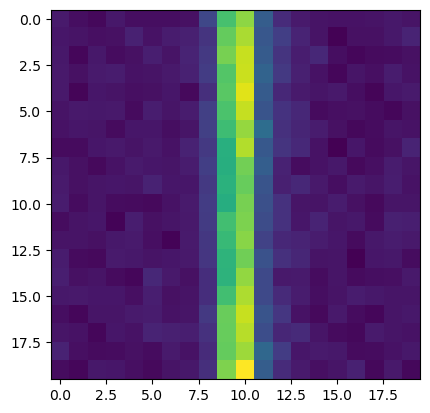

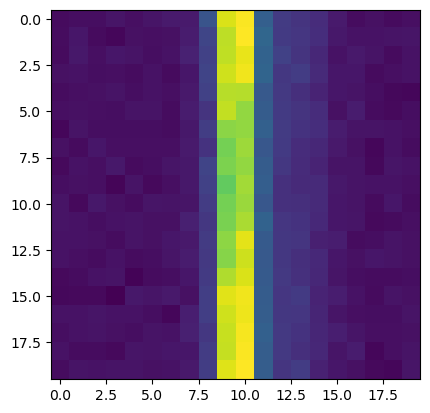

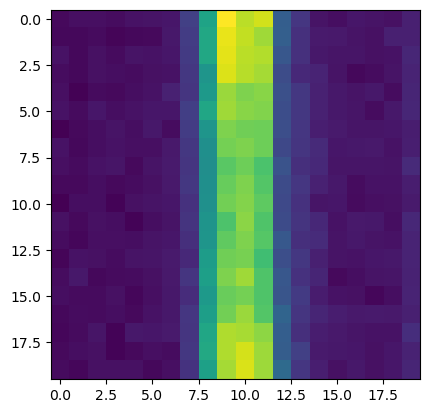

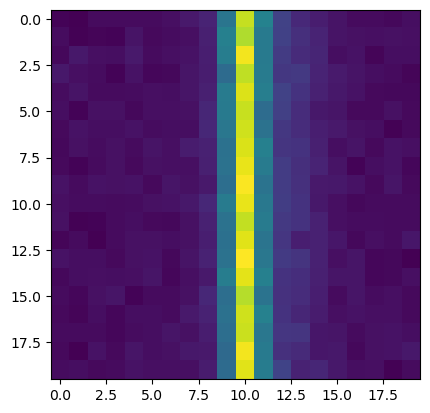

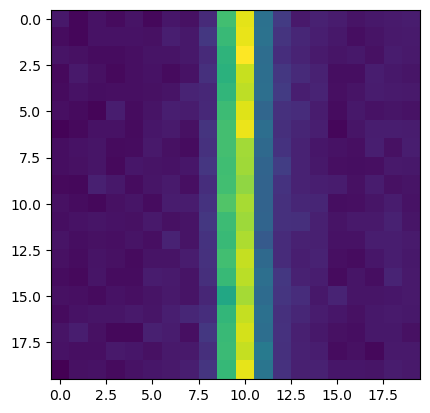

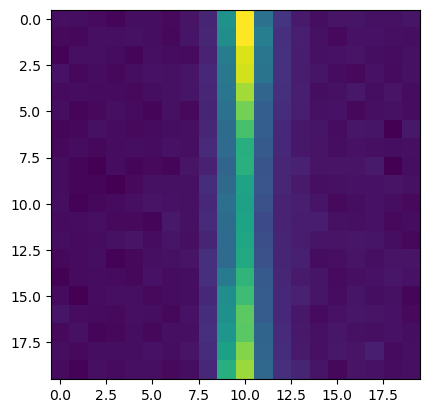

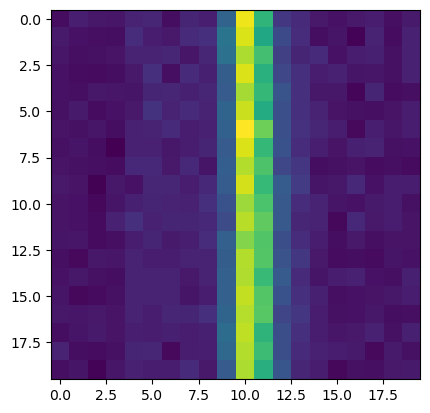

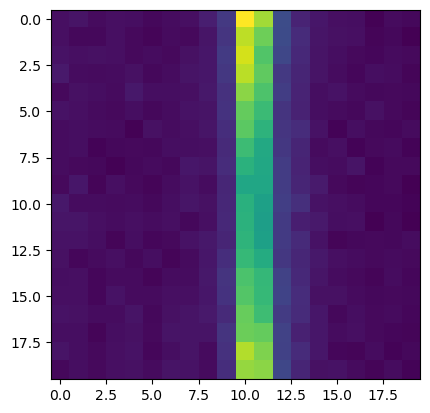

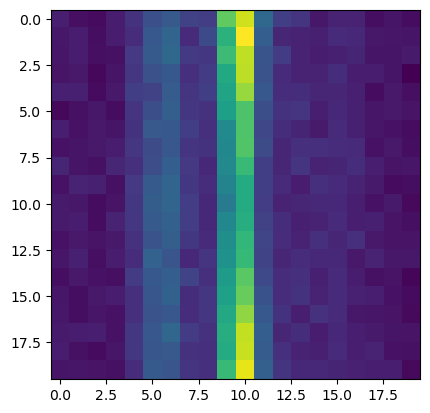

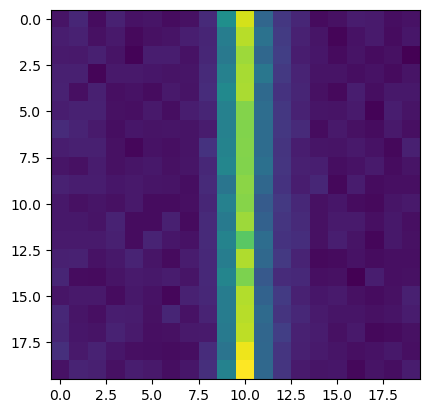

In [27]:
for i in range(len(stamp)):
    plt.imshow(stamp[i])
    plt.show()

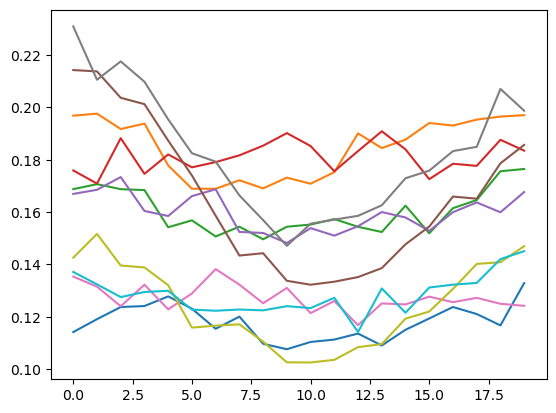

In [28]:
for i in range(stamp.shape[0]):
    plt.plot(stamp[i,:,10])

In [13]:
stampn = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/images/ztf_20220820237546_000798_zr_c01_x_0001._1_stamps.npy")

In [12]:
infon = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/info/ztf_20220820237546_000798_zr_c01_x_0001._1_stamps_info.npy")

In [31]:
infon

array([[9.000e-01, 4.000e+00, 1.510e+02, 1.713e+03],
       [9.500e-01, 7.000e+00, 4.350e+02, 2.006e+03],
       [8.000e-01, 4.000e+00, 1.045e+03, 5.850e+02],
       [9.900e-01, 6.000e+00, 1.249e+03, 1.748e+03],
       [9.900e-01, 6.000e+00, 1.383e+03, 2.636e+03],
       [8.000e-01, 4.000e+00, 1.880e+03, 2.457e+03],
       [9.950e-01, 4.000e+00, 2.803e+03, 1.773e+03],
       [5.000e-01, 7.000e+00, 2.962e+03, 1.222e+03]])

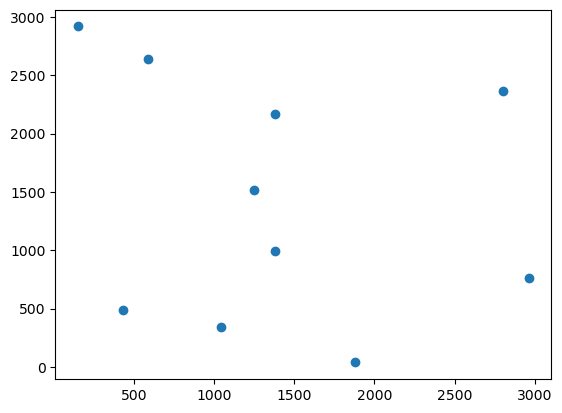

In [16]:
plt.scatter(info[:,2],info[:,3])

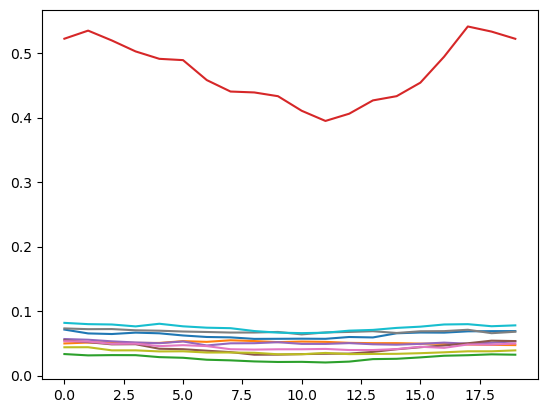

In [14]:
for i in range(stampn.shape[0]):
    plt.plot(stampn[i,:,10])

In [39]:
image_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/"

In [40]:
image_file = np.load(image_path+"ztf_20220820237546_000798_zr_c01_x_0003._1_implanted_neg.npy")

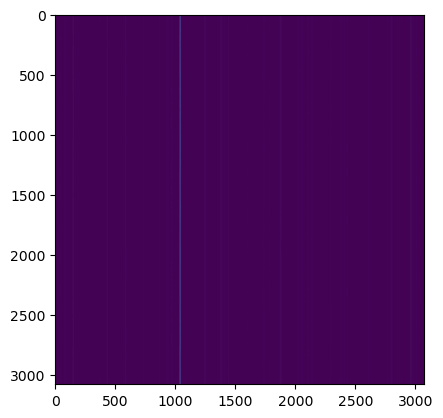

In [59]:
plt.imshow(image_file)

In [60]:
from scipy.signal import find_peaks

In [114]:
averages = np.average(image_file[20:-20,20:-20], axis=0) #cut off edges
peaks, heights = find_peaks(averages, height=(None, None))
min_height = np.sort(heights['peak_heights'])[-10]
tall_map = heights['peak_heights']>=min_height
tall_peaks = peaks[tall_map]+20

In [116]:
tall_peaks

array([ 150,  434, 1041, 1045, 1248, 1379, 1383, 1880, 2803, 2962])

In [112]:
tall_peaks

array([ 150,  434, 1041, 1045, 1248, 1379, 1383, 1880, 2803, 2962])

In [101]:
heights['peak_heights']

array([ 156.10496521,  152.81774902,  162.22715759,  157.16604614,
        160.86790466,  151.72853088,  169.50700378,  150.75906372,
        190.08740234,  150.7177887 ,  153.34341431,  168.18132019,
        150.76231384,  149.91938782,  152.75805664,  222.27708435,
        151.41355896,  153.92776489,  189.53599548,  159.19250488,
        151.35874939,  156.85961914,  159.70347595,  151.57533264,
        154.84339905,  152.22406006,  151.34294128,  533.434021  ,
        237.74833679,  159.23027039,  150.13916016,  203.89051819,
        161.18914795,  150.15623474,  149.01533508,  149.37306213,
        219.1696167 ,  152.08447266,  149.43548584,  166.50491333,
        150.08737183,  148.93434143,  148.74665833,  150.72676086,
        155.41616821,  160.89126587,  149.11039734,  156.34532166,
        152.20095825,  148.70683289,  152.23631287,  150.23553467,
        152.21499634,  150.36895752,  157.60482788,  148.43994141,
        148.31872559,  154.89015198,  160.03788757,  150.35609

In [76]:
[heights['peak_heights']>300].indices

AttributeError: 'list' object has no attribute 'indices'

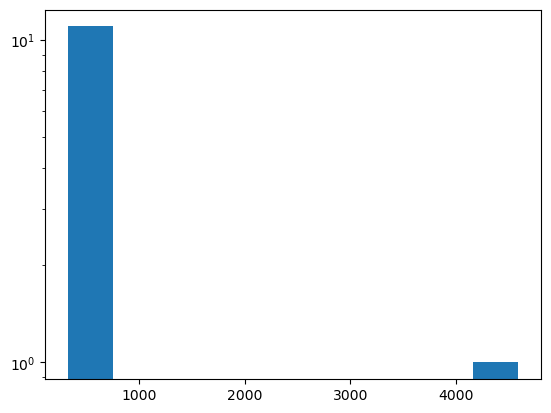

In [74]:
plt.hist(heights['peak_heights'][heights['peak_heights']>300])
plt.yscale("log")

In [59]:
def get_10_trans_stamps_w_offcenter(image, sigmas, intensities, center_values, counter, plot=False):
    """
    mmmmmm thinking

    """
    intensity_counter = counter
    y_counter = counter
    
    averages = np.average(image[20:-20,20:-20], axis=0) #cut off edges
    peaks, heights = find_peaks(averages, height=(None, None))
    min_height = np.sort(heights['peak_heights'])[-10]
    tall_map = heights['peak_heights']>=min_height
    tall_peaks = peaks[tall_map]+20
    
    implanted = image
    stamps_implanted = []
    background_stamps = []
    stamp_info = []  # empty list for adding info for implanted transients
    background_info = []
    for streak_x_val in tall_peaks:
        center_value_y = center_values[y_counter]
        intensity = intensities[intensity_counter]
        sigma = sigmas[intensity_counter]
        y_counter += 1
        intensity_counter += 1
        implanted, maxcol = imp.implant_transient_full_image(
            implanted, streak_x_val, center_value_y, intensity, sigma, norm=True
        )
        # print("intensity "+str(intensity))
        # print("xval "+str(streak_x_val))
        intensity_sigma = (intensity, sigma, maxcol,center_value_y)
        stamp_info.append((intensity, sigma, maxcol,center_value_y, 0))
        stamp = imp.get_stamp(implanted, maxcol, center_value_y, plot=plot)
        stamps_implanted.append(stamp)
        offset_true = [1,2]
        for offset in np.concatenate((offset_true, np.negative(offset_true))):
            stamp = imp.get_stamp(implanted, maxcol+offset, center_value_y, plot=plot)
            stamps_implanted.append(stamp)
            stamp_info.append((intensity, sigma, maxcol,center_value_y, offset))
        offset_false = np.arange(4,25)
        for offset in np.concatenate((offset_false, np.negative(offset_false))):
            stamp = imp.get_stamp(implanted, maxcol+offset, center_value_y, plot=plot)
            background_stamps.append(stamp)
            background_info.append((intensity, sigma, maxcol,center_value_y, offset))       
    return stamps_implanted, stamp_info, background_stamps, background_info

In [31]:
offset_true = [1,2]

In [37]:
np.concatenate((offset_true, np.negative(offset_true)))

array([ 1,  2, -1, -2])

In [ ]:
image_file

In [42]:
from scipy.signal import find_peaks

In [63]:
stamps_implanted

NameError: name 'stamps_implanted' is not defined

In [48]:
import implantation_functions as imp

In [64]:
np.full(10,5)

array([5, 5, 5, 5, 5, 5, 5, 5, 5, 5])

In [66]:
stamps_implanted, stamp_info, background_stamps, background_info=get_10_trans_stamps_w_offcenter(image_file, np.full(10,5), np.full(10,5), np.full(10,30), counter=0, plot=False)

stamp info:  (5, 5, 150, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 434, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1041, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1041, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1249, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1383, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1383, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 1880, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 2803, 30)
REAL
BACKGROUND
stamp info:  (5, 5, 2962, 30)
REAL
BACKGROUND


In [67]:
background_info

[(5, 5, 150, 30, 4),
 (5, 5, 150, 30, 5),
 (5, 5, 150, 30, 6),
 (5, 5, 150, 30, 7),
 (5, 5, 150, 30, 8),
 (5, 5, 150, 30, 9),
 (5, 5, 150, 30, 10),
 (5, 5, 150, 30, 11),
 (5, 5, 150, 30, 12),
 (5, 5, 150, 30, 13),
 (5, 5, 150, 30, 14),
 (5, 5, 150, 30, 15),
 (5, 5, 150, 30, 16),
 (5, 5, 150, 30, 17),
 (5, 5, 150, 30, 18),
 (5, 5, 150, 30, 19),
 (5, 5, 150, 30, 20),
 (5, 5, 150, 30, 21),
 (5, 5, 150, 30, 22),
 (5, 5, 150, 30, 23),
 (5, 5, 150, 30, 24),
 (5, 5, 150, 30, -4),
 (5, 5, 150, 30, -5),
 (5, 5, 150, 30, -6),
 (5, 5, 150, 30, -7),
 (5, 5, 150, 30, -8),
 (5, 5, 150, 30, -9),
 (5, 5, 150, 30, -10),
 (5, 5, 150, 30, -11),
 (5, 5, 150, 30, -12),
 (5, 5, 150, 30, -13),
 (5, 5, 150, 30, -14),
 (5, 5, 150, 30, -15),
 (5, 5, 150, 30, -16),
 (5, 5, 150, 30, -17),
 (5, 5, 150, 30, -18),
 (5, 5, 150, 30, -19),
 (5, 5, 150, 30, -20),
 (5, 5, 150, 30, -21),
 (5, 5, 150, 30, -22),
 (5, 5, 150, 30, -23),
 (5, 5, 150, 30, -24),
 (5, 5, 434, 30, 4),
 (5, 5, 434, 30, 5),
 (5, 5, 434, 30, 6),
 (5,

In [89]:
toload = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_neg/images/ztf_20221017148750_000831_zi_c03_x_0007._1_stamps.npy"


In [90]:
loaded = np.load(toload)

In [91]:
np.shape(loaded)

(50, 20, 20)

In [83]:
toload_info = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_neg/info/ztf_20221017148750_000831_zi_c03_x_0007._1_stamps_info.npy"

In [85]:
np.load(toload_info)

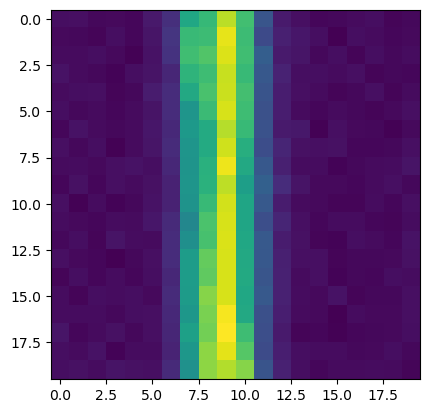

In [92]:
plt.imshow(loaded[31])

In [116]:
len("ztf_20221020138241_000686_zi_c08_x_0007._1_stamps_streak.npy")

60

In [117]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_background/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    if len(image_filename)>59:
        info_filename = image_filename[:50] + "info_streak.npy"
    else:
        info_filename = image_filename[:50] + "info_"+image_filename[-7:]
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)

ztf_20221020138241_000686_zi_c08_x_0007._1_stamps_streak.npy
(420, 20, 20)
(420, 5)
ztf_20220820237546_000798_zr_c07_x_0003._4_stamps_pos.npy
(420, 20, 20)
(420, 5)
ztf_20221014162894_000802_zg_c02_x_0028._1_stamps_pos.npy
(420, 20, 20)
(420, 5)
ztf_20221017148750_000831_zi_c04_x_0012._1_stamps_streak.npy
(420, 20, 20)
(420, 5)
ztf_20221020138241_000686_zi_c01_x_0017._3_stamps_streak.npy
(420, 20, 20)
(420, 5)
ztf_20221020138241_000686_zi_c08_x_0007._4_stamps_neg.npy
(420, 20, 20)
(420, 5)
ztf_20221014162894_000802_zg_c01_x_0014._2_stamps_neg.npy
(420, 20, 20)
(420, 5)
ztf_20221020138241_000686_zi_c07_x_0020._4_stamps_pos.npy
(420, 20, 20)
(420, 5)
ztf_20221014162894_000802_zg_c03_x_0003._4_stamps_pos.npy
(420, 20, 20)
(420, 5)
ztf_20221014162894_000802_zg_c01_x_0022._3_stamps_pos.npy
(420, 20, 20)
(420, 5)
ztf_20221020138241_000686_zi_c02_x_0001._1_stamps_neg.npy
(420, 20, 20)
(420, 5)
ztf_20221020138241_000686_zi_c01_x_0016._2_stamps_streak.npy
(420, 20, 20)
(420, 5)
ztf_202210141628

KeyboardInterrupt: 

In [124]:
all_bg_stamps = all_pos_stamps
all_bg_stamps_info = all_pos_stamps_info

In [125]:
all_bg_stamps_info

array([[ 0.000e+00,  0.000e+00,  2.160e+02,  2.074e+03,  4.000e+00],
       [ 0.000e+00,  0.000e+00,  2.160e+02,  2.074e+03,  5.000e+00],
       [ 0.000e+00,  0.000e+00,  2.160e+02,  2.074e+03,  6.000e+00],
       ...,
       [ 7.000e-01,  6.000e+00,  2.465e+03,  9.400e+01, -2.200e+01],
       [ 7.000e-01,  6.000e+00,  2.465e+03,  9.400e+01, -2.300e+01],
       [ 7.000e-01,  6.000e+00,  2.465e+03,  9.400e+01, -2.400e+01]])

In [123]:
len(all_pos_stamps)

156240

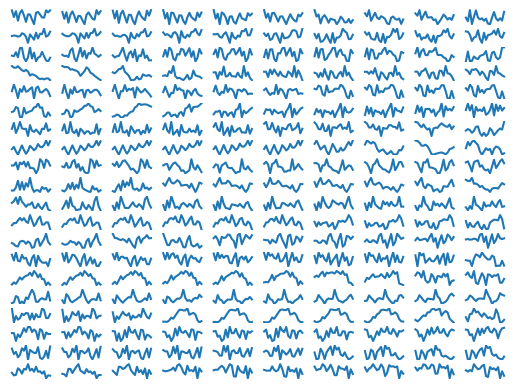

In [118]:
fig, ax = plt.subplots(20, 10)
for i in range(20):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[3*i * 10 + h], axis=1))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

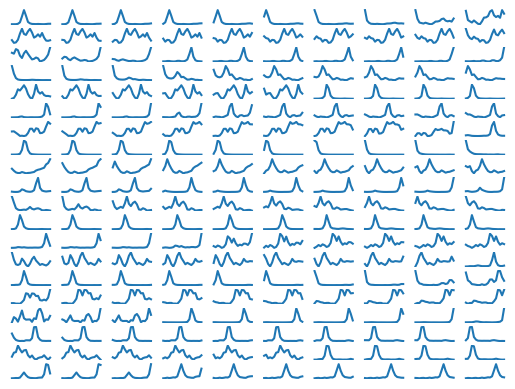

In [120]:
fig, ax = plt.subplots(20, 10)
for i in range(20):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[3*i * 10 + h], axis=0))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

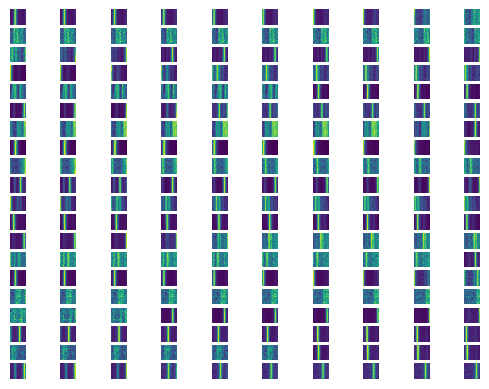

In [122]:
fig, ax = plt.subplots(20, 10)
for i in range(20):
    for h in range(10):
        # print(i, h)
        ax[i, h].imshow(np.sqrt(all_pos_stamps[3*i * 10 + h]))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

In [128]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_pos/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)

ztf_20221020138241_000686_zi_c05_x_0019._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c01_x_0022._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c03_x_0002._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c05_x_0000._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c01_x_0014._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0018._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0000._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0001._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0019._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c02_x_0001._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c06_x_0002._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c13_x_0003._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c02_x_0015._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802

In [129]:
len(all_pos_stamps)

57400

In [133]:
int(57400/28700)

2

In [ ]:
28700.0 should be either positive and smaller than the number of samples 57400

In [130]:
fpath_trans = "/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_neg/"

# all_trans_stamps =[] #np.zeros((len(os.listdir(fpath_trans)), 10, 20, 20))

image_path = fpath_trans + "images/"
info_path = fpath_trans + "info/"

for i, file in enumerate(os.listdir(image_path)):
    image_filename = os.fsdecode(file)
    image_filename_full = image_path + image_filename
    print(image_filename)
    info_filename = image_filename[:-4] + "_info.npy"
    info_filename_full = info_path + info_filename
    trans = np.load(image_filename_full)
    trans_arr = np.array(trans)
    infos = np.load(info_filename_full)
    infos_arr = np.array(infos)
    print(np.shape(trans))
    print(np.shape(infos))
    # all_trans_stamps.append(trans_arr)
    if i == 0:
        all_pos_stamps = trans_arr
        all_pos_stamps_info = infos_arr
    else:
        all_pos_stamps = np.concatenate((all_pos_stamps, trans_arr), axis=0)
        all_pos_stamps_info = np.concatenate((all_pos_stamps_info, infos_arr), axis=0)

ztf_20221014162894_000802_zg_c01_x_0003._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c05_x_0021._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0021._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20220820237546_000798_zr_c07_x_0001._3_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c03_x_0015._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c02_x_0007._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c01_x_0000._1_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c03_x_0004._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c02_x_0016._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221020138241_000686_zi_c06_x_0023._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c04_x_0012._4_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831_zi_c05_x_0000._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221014162894_000802_zg_c02_x_0018._2_stamps.npy
(50, 20, 20)
(50, 5)
ztf_20221017148750_000831

In [131]:
len(all_pos_stamps)

57400

In [127]:
len(all_pos_stamps)

57400

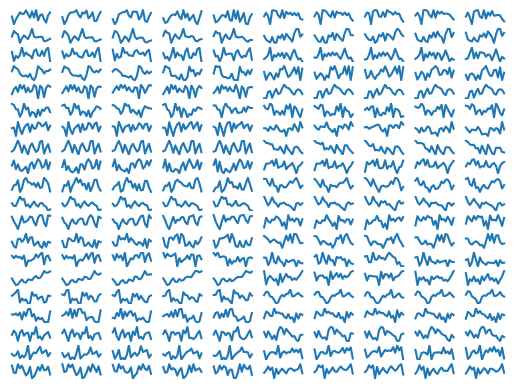

In [106]:
fig, ax = plt.subplots(20, 10)
for i in range(20):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[3*i * 10 + h], axis=1))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()

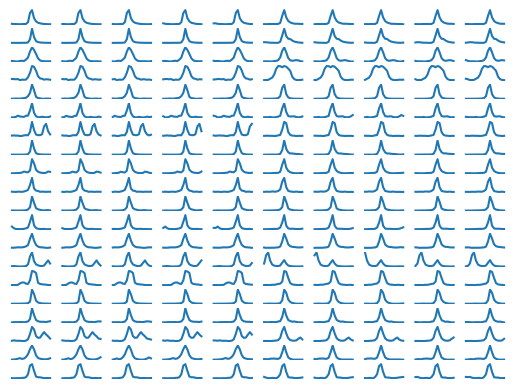

In [105]:
fig, ax = plt.subplots(20, 10)
for i in range(20):
    for h in range(10):
        # print(i, h)
        ax[i, h].plot(np.sum(all_pos_stamps[3*i * 10 + h], axis=0))
        # ax[i, h].imshow(all_neg_stamps[i*10 + h])
        ax[i, h].axis("off")
fig.show()